# 03 | SQL answers, KPI scorecard and statistical test

This notebook queries the SQLite clean table with `pandas.read_sql`, defines each KPI, tests a weekday/weekend order-revenue difference, and exports stakeholder reports. All amounts are KES; one cleaned row is one order.

In [1]:
from pathlib import Path
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from scipy import stats
from openpyxl.styles import Font, PatternFill, Alignment

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)
with sqlite3.connect(ROOT / "data" / "duka_sales.db") as connection:
    sales = pd.read_sql("SELECT * FROM sales", connection, parse_dates=["order_date"])
    kpis = pd.read_sql("SELECT COUNT(DISTINCT order_id) AS orders, SUM(revenue) AS revenue_kes, SUM(revenue) / COUNT(DISTINCT order_id) AS aov_kes, SUM(units_sold) AS units FROM sales", connection)
    branches_over_5m = pd.read_sql("SELECT branch, COUNT(*) AS orders, SUM(revenue) AS revenue_kes FROM sales GROUP BY branch HAVING SUM(revenue) > 5000000 ORDER BY revenue_kes DESC", connection)
    category_ranks = pd.read_sql("WITH p AS (SELECT category, product, SUM(revenue) revenue_kes FROM sales GROUP BY category, product) SELECT category, product, revenue_kes, RANK() OVER (PARTITION BY category ORDER BY revenue_kes DESC) category_rank FROM p ORDER BY category, category_rank", connection)
    channel_join = pd.read_sql("WITH bc AS (SELECT branch, channel, COUNT(*) orders, SUM(revenue) revenue_kes FROM sales GROUP BY branch, channel) SELECT a.branch, a.orders online_orders, a.revenue_kes online_revenue_kes, b.orders store_orders, b.revenue_kes store_revenue_kes FROM bc a JOIN bc b ON a.branch=b.branch WHERE a.channel='Online' AND b.channel='In-store' ORDER BY a.branch", connection)
    monthly = pd.read_sql("WITH m AS (SELECT strftime('%Y-%m', order_date) month, SUM(revenue) revenue_kes FROM sales GROUP BY strftime('%Y-%m', order_date)) SELECT month, revenue_kes, revenue_kes-LAG(revenue_kes) OVER (ORDER BY month) change_vs_prior_month_kes FROM m ORDER BY month", connection)
print("KPI scorecard definitions: H1 revenue = sum of units times price; orders = distinct order IDs; AOV = revenue / distinct orders; units = sum of units.")
display(kpis.round(2))
print("SQL: branches above KES 5m (GROUP BY + HAVING)"); display(branches_over_5m)
print("SQL: products ranked within category (window RANK)"); display(category_ranks)
print("SQL: online and store revenue by branch (JOIN)"); display(channel_join)
print("SQL: monthly revenue and prior-month change (LAG)"); display(monthly)

KPI scorecard definitions: H1 revenue = sum of units times price; orders = distinct order IDs; AOV = revenue / distinct orders; units = sum of units.


,orders,revenue_kes,aov_kes,units
0,1000,52464100.0,52464.1,1699


SQL: branches above KES 5m (GROUP BY + HAVING)


,branch,orders,revenue_kes
0,Mombasa,132,8180000.0
1,Nakuru,127,6860500.0
2,Nairobi,121,6775000.0
3,Kisumu,120,6671800.0
4,Westlands,118,6605900.0
5,Nyeri,136,6558700.0
6,Eldoret,137,5885500.0


SQL: products ranked within category (window RANK)


,category,product,revenue_kes,category_rank
0,Accessories,Power Bank 20K,697300.0,1
1,Audio,Wireless Headphones,1121600.0,1
2,Audio,Bluetooth Speaker,1109900.0,2
3,Computing,Laptop Pro 14,16840500.0,1
4,Computing,Chromebook Air,4995000.0,2
5,Computing,Tablet 10in,3677500.0,3
6,Mobile,Smartphone X,5952800.0,1
7,Mobile,Budget Smartphone,2615000.0,2
8,Networking,Wi-Fi Router AX,1432900.0,1
9,Television,4K Television 43in,6683000.0,1


SQL: online and store revenue by branch (JOIN)


,branch,online_orders,online_revenue_kes,store_orders,store_revenue_kes
0,Eldoret,48,1906500.0,89,3979000.0
1,Kisumu,40,1992900.0,80,4678900.0
2,Mombasa,55,4301400.0,77,3878600.0
3,Nairobi,40,1962300.0,81,4812700.0
4,Nakuru,53,3017100.0,74,3843400.0
5,Nyeri,50,2733700.0,86,3825000.0
6,Thika,33,1684200.0,76,3242500.0
7,Westlands,36,1900000.0,82,4705900.0


SQL: monthly revenue and prior-month change (LAG)


,month,revenue_kes,change_vs_prior_month_kes
0,2026-01,8121500.0,NaN
1,2026-02,6703000.0,-1418500.0
2,2026-03,7645500.0,942500.0
3,2026-04,9387200.0,1741700.0
4,2026-05,9604800.0,217600.0
5,2026-06,11002100.0,1397300.0


## Statistical test: weekday vs weekend order revenue

Welch's independent-samples t-test compares mean order revenue between weekday and weekend orders, without assuming equal variances. H0: the two population means are equal; H1: they differ. Use alpha = 0.05. The confidence interval is for weekend minus weekday mean. This exploratory synthetic sample does not establish a causal day-of-week effect.

In [2]:
sales["day_type"] = np.where(sales["order_date"].dt.dayofweek >= 5, "Weekend", "Weekday")
weekday = sales.loc[sales.day_type == "Weekday", "revenue"].to_numpy(dtype=float)
weekend = sales.loc[sales.day_type == "Weekend", "revenue"].to_numpy(dtype=float)
test = stats.ttest_ind(weekend, weekday, equal_var=False)
se = np.sqrt(weekend.var(ddof=1) / len(weekend) + weekday.var(ddof=1) / len(weekday))
df = (weekend.var(ddof=1)/len(weekend) + weekday.var(ddof=1)/len(weekday))**2 / ((weekend.var(ddof=1)/len(weekend))**2/(len(weekend)-1) + (weekday.var(ddof=1)/len(weekday))**2/(len(weekday)-1))
difference = weekend.mean() - weekday.mean()
ci = (difference - stats.t.ppf(0.975, df)*se, difference + stats.t.ppf(0.975, df)*se)
result = pd.DataFrame([{"weekday_n": len(weekday), "weekday_mean_kes": weekday.mean(), "weekend_n": len(weekend), "weekend_mean_kes": weekend.mean(), "difference_weekend_minus_weekday_kes": difference, "95pct_ci_low_kes": ci[0], "95pct_ci_high_kes": ci[1], "welch_t": test.statistic, "p_value": test.pvalue}])
display(result.round(3))
if test.pvalue < 0.05:
    print(f"At alpha=0.05, reject equal means: the observed weekend-minus-weekday mean difference is KES {difference:,.0f} (95% CI KES {ci[0]:,.0f} to {ci[1]:,.0f}; p={test.pvalue:.4g}). This is an association in synthetic orders, not a causal effect.")
else:
    print(f"At alpha=0.05, do not reject equal means (difference KES {difference:,.0f}; 95% CI KES {ci[0]:,.0f} to {ci[1]:,.0f}; p={test.pvalue:.4g}). The data do not establish equal means or a causal effect.")

C:\Users\SEENOI HPF\AppData\Local\Temp\ipykernel_31668\2743405515.py:1: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  sales["day_type"] = np.where(sales["order_date"].dt.dayofweek >= 5, "Weekend", "Weekday")


,weekday_n,weekday_mean_kes,weekend_n,weekend_mean_kes,difference_weekend_minus_weekday_kes,95pct_ci_low_kes,95pct_ci_high_kes,welch_t,p_value
0,698,53179.083,302,50811.589,-2367.494,-11471.001,6736.013,-0.511,0.61


At alpha=0.05, do not reject equal means (difference KES -2,367; 95% CI KES -11,471 to 6,736; p=0.6097). The data do not establish equal means or a causal effect.


## Stakeholder workbook and visual report exports

The workbook contains filterable summary tables (no customer-level records). The static dashboard is not an interactive Looker Studio dashboard. The executive memo and presentation are generated from the same cleaned dataset and KPI definitions.

Saved filterable workbook: C:\Users\SEENOI HPF\OneDrive\Desktop\expense tracker\postgres-performance-lab\plp-capstone-a-seenoinaurori\reports\stakeholder_summary.xlsx


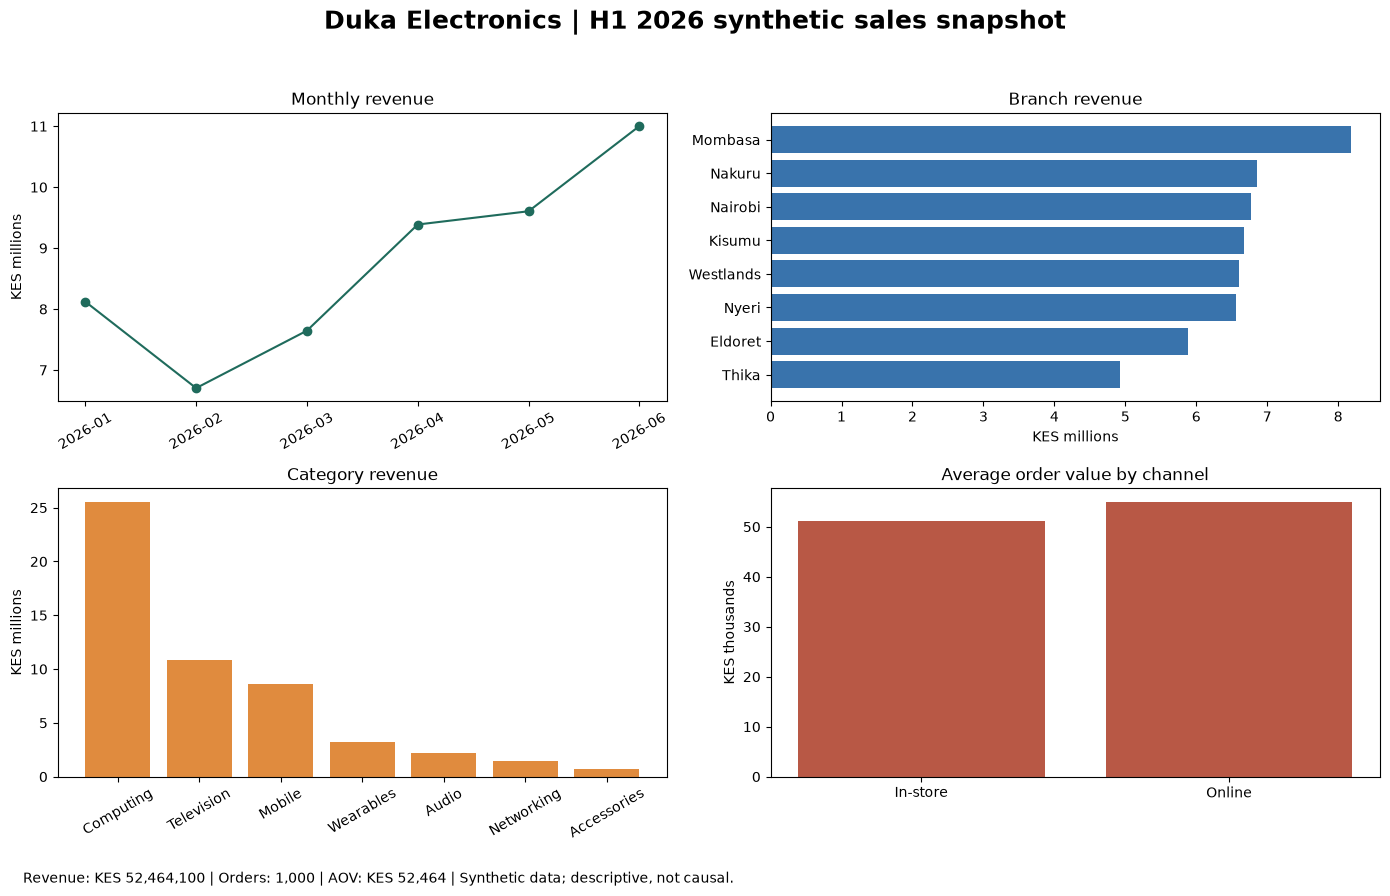

In [3]:
branch = sales.groupby("branch", as_index=False).agg(orders=("order_id", "nunique"), revenue_kes=("revenue", "sum"), average_order_value_kes=("revenue", "mean")).sort_values("revenue_kes", ascending=False)
category = sales.groupby("category", as_index=False).agg(orders=("order_id", "nunique"), units=("units_sold", "sum"), revenue_kes=("revenue", "sum")).sort_values("revenue_kes", ascending=False)
month = sales.assign(month=sales.order_date.dt.to_period("M").astype(str)).groupby("month", as_index=False).agg(orders=("order_id", "nunique"), revenue_kes=("revenue", "sum"))
channel = sales.groupby("channel", as_index=False).agg(orders=("order_id", "nunique"), revenue_kes=("revenue", "sum"), average_order_value_kes=("revenue", "mean"))
product = sales.groupby(["category", "product"], as_index=False).agg(orders=("order_id", "nunique"), units=("units_sold", "sum"), revenue_kes=("revenue", "sum")).sort_values("revenue_kes", ascending=False)
scorecard = pd.DataFrame([{"metric": "H1 revenue (KES)", "value": kpis.loc[0,"revenue_kes"], "definition": "Sum of units_sold times unit_price across clean orders"}, {"metric": "Orders", "value": kpis.loc[0,"orders"], "definition": "Distinct order_id count"}, {"metric": "Average order value (KES)", "value": kpis.loc[0,"aov_kes"], "definition": "H1 revenue divided by distinct order count"}, {"metric": "Units sold", "value": kpis.loc[0,"units"], "definition": "Sum of units_sold"}])
workbook = REPORTS / "stakeholder_summary.xlsx"
with pd.ExcelWriter(workbook, engine="openpyxl") as writer:
    for sheet, table in [("KPI Scorecard", scorecard), ("Branch Summary", branch), ("Category Summary", category), ("Monthly Summary", month), ("Channel Summary", channel), ("Product Summary", product)]:
        table.to_excel(writer, sheet_name=sheet, index=False)
    for ws in writer.book.worksheets:
        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions
        for cell in ws[1]:
            cell.font = Font(bold=True, color="FFFFFF")
            cell.fill = PatternFill("solid", fgColor="1F6B5C")
            cell.alignment = Alignment(wrap_text=True)
        for column_cells in ws.columns:
            width = min(max(max(len(str(cell.value or "")) for cell in column_cells) + 2, 12), 42)
            ws.column_dimensions[column_cells[0].column_letter].width = width
print(f"Saved filterable workbook: {workbook}")

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle("Duka Electronics | H1 2026 synthetic sales snapshot", fontsize=18, fontweight="bold")
axes[0,0].plot(month.month, month.revenue_kes/1e6, marker="o", color="#1f6b5c"); axes[0,0].set(title="Monthly revenue", ylabel="KES millions"); axes[0,0].tick_params(axis="x", rotation=30)
axes[0,1].barh(branch.branch, branch.revenue_kes/1e6, color="#3973ac"); axes[0,1].invert_yaxis(); axes[0,1].set(title="Branch revenue", xlabel="KES millions")
axes[1,0].bar(category.category, category.revenue_kes/1e6, color="#e08b3e"); axes[1,0].set(title="Category revenue", ylabel="KES millions"); axes[1,0].tick_params(axis="x", rotation=30)
axes[1,1].bar(channel.channel, channel.average_order_value_kes/1000, color="#b85845"); axes[1,1].set(title="Average order value by channel", ylabel="KES thousands")
fig.text(0.02, 0.01, f"Revenue: KES {kpis.loc[0,'revenue_kes']:,.0f} | Orders: {int(kpis.loc[0,'orders']):,} | AOV: KES {kpis.loc[0,'aov_kes']:,.0f} | Synthetic data; descriptive, not causal.", fontsize=10)
fig.tight_layout(rect=(0,0.04,1,0.95))
fig.savefig(REPORTS / "dashboard.png", dpi=180, bbox_inches="tight")
with PdfPages(REPORTS / "visual_report.pdf") as pdf:
    pdf.savefig(fig, bbox_inches="tight")
plt.show()

In [4]:
top_branch = branch.iloc[0]
top_category = category.iloc[0]
best_month = month.loc[month.revenue_kes.idxmax()]
weak_month = month.loc[month.revenue_kes.idxmin()]
idea = "Prioritise H2 inventory and marketing tests using branch/category performance, but validate stock, margin and costs before reallocating budget."
findings = [f"H1 synthetic orders generated KES {kpis.loc[0,'revenue_kes']:,.0f} across {int(kpis.loc[0,'orders']):,} orders (AOV KES {kpis.loc[0,'aov_kes']:,.0f}).", f"{top_branch.branch} led branch revenue at KES {top_branch.revenue_kes:,.0f}; {top_category.category} led category revenue at KES {top_category.revenue_kes:,.0f}.", f"{best_month.month} was the strongest month (KES {best_month.revenue_kes:,.0f}); {weak_month.month} was the weakest (KES {weak_month.revenue_kes:,.0f}).", f"Welch test weekend minus weekday mean: KES {difference:,.0f} (95% CI {ci[0]:,.0f} to {ci[1]:,.0f}; p={test.pvalue:.4g})."]
recommendations = ["Protect availability for the strongest revenue categories and audit stock-outs before placing H2 orders.", "Run a time-boxed, measurable branch marketing pilot with a holdout or baseline; compare incremental gross margin, not revenue alone.", "Investigate monthly peaks and troughs with promotion, stock and cost data before changing budgets."]
limitations = "All orders are synthetic and generated for teaching. Costs, inventory, promotions and customer cohorts are absent. Results are descriptive; weekday/weekend test assumptions and repeated product/branch comparisons limit inference. No causal or real-business conclusions are warranted."
fig, ax = plt.subplots(figsize=(11, 8.5)); ax.axis("off")
text = "BIG IDEA\n" + idea + "\n\nKEY FINDINGS\n" + "\n".join("- " + x for x in findings) + "\n\nRECOMMENDATIONS\n" + "\n".join("- " + x for x in recommendations) + "\n\nBUSINESS IMPACT\nUse the KES performance baseline to direct a measured 90-day inventory and marketing pilot; evaluate lift in gross margin and sell-through before scaling. Impact is a proposed measurement plan, not a forecast.\n\nLIMITATIONS\n" + limitations
ax.text(0.04, 0.96, "EXECUTIVE SUMMARY | DUKA ELECTRONICS | H1 2026", fontsize=16, fontweight="bold", va="top", color="#1f6b5c")
ax.text(0.04, 0.89, text, fontsize=10.4, va="top", wrap=True, linespacing=1.35)
fig.savefig(REPORTS / "executive_summary.pdf", bbox_inches="tight")
plt.close(fig)

slide_titles = ["Decision context", "H1 KPI scorecard", "Monthly sales trend", "Branch performance", "Category mix", "Channel basket comparison", "Weekday/weekend test", "Recommendations and limits"]
with PdfPages(REPORTS / "slides.pdf") as pdf:
    for i, title in enumerate(slide_titles):
        fig, ax = plt.subplots(figsize=(12, 6.75)); ax.axis("off")
        ax.text(0.06,0.92,title,fontsize=25,fontweight="bold",color="#1f6b5c",va="top")
        if i == 0: body = "Stakeholder: Duka commercial lead\nDecision: where to focus H2 inventory and marketing\nEvidence: synthetic H1 2026 order data\nQuestion: which mix of branch, product, month and channel deserves a measured test?"
        elif i == 1: body = f"Revenue  KES {kpis.loc[0,'revenue_kes']:,.0f}\nOrders  {int(kpis.loc[0,'orders']):,}\nAverage order value  KES {kpis.loc[0,'aov_kes']:,.0f}\nUnits  {int(kpis.loc[0,'units']):,}"
        elif i == 2: body = "Revenue by month (KES millions)\n" + "  ".join(f"{r.month}: {r.revenue_kes/1e6:.2f}" for r in month.itertuples())
        elif i == 3: body = "Revenue by branch (KES millions)\n" + "\n".join(f"{r.branch}: {r.revenue_kes/1e6:.2f}" for r in branch.itertuples())
        elif i == 4: body = "Revenue by category (KES millions)\n" + "\n".join(f"{r.category}: {r.revenue_kes/1e6:.2f}" for r in category.itertuples())
        elif i == 5: body = "Average order value (KES)\n" + "\n".join(f"{r.channel}: {r.average_order_value_kes:,.0f} across {r.orders:,} orders" for r in channel.itertuples()) + "\nDescriptive comparison only; not causal."
        elif i == 6: body = f"Weekend minus weekday average order revenue: KES {difference:,.0f}\n95% CI: KES {ci[0]:,.0f} to {ci[1]:,.0f}\nWelch t={test.statistic:.2f}, p={test.pvalue:.4g}\n" + ("Reject equal means at alpha=.05." if test.pvalue < .05 else "Do not reject equal means at alpha=.05.")
        else: body = "Pilot stock and marketing allocation; track incremental gross margin and sell-through; compare with baseline/holdout before scaling.\n\nLimits: synthetic data; no costs, promotions or stock-outs; no causal claims."
        ax.text(0.07,0.75,body,fontsize=18,va="top",linespacing=1.7)
        ax.text(0.07,0.05,"Duka Electronics | H1 2026 | Synthetic teaching data",fontsize=9,color="#555555")
        pdf.savefig(fig,bbox_inches="tight"); plt.close(fig)
print(f"Saved reports: {REPORTS}")

Saved reports: C:\Users\SEENOI HPF\OneDrive\Desktop\expense tracker\postgres-performance-lab\plp-capstone-a-seenoinaurori\reports
